In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


import gc

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path





# Features  
the first step: extracting fed rate features from postgresql can be found here: "/home/lelandmesford/Projects/dbt_projects/predict_car_sales_ML_modeling/archive_data/sufficient_data/effective_and_four_year_fed_rates_2010_2026/fed_rates_2010-2026.ipynb"

In [221]:
imported_features = pd.read_csv('archive_data/sufficient_data/effective_and_four_year_fed_rates_2010_2026/fed_rates_2010-2026_raw.csv')
print(f"Shape: {imported_features.shape}\nNaN: {imported_features.isna().sum().sum()}")
imported_features.sample(10)

Shape: (191, 3)
NaN: 129


,observation_date,effective_rate,four_year_installment
8,2011-07-01,0.07,5.89
184,2026-03-01,3.64,NaN
91,2018-06-01,1.82,NaN
127,2021-06-01,0.08,NaN
107,2019-10-01,1.83,5.45
165,2024-08-01,5.33,NaN
10,2011-09-01,0.08,NaN
9,2011-08-01,0.10,NaN
134,2022-01-01,0.08,4.87
72,2016-11-01,0.41,NaN


In [222]:
imported_features.dtypes

observation_date          object
effective_rate           float64
four_year_installment    float64
dtype: object

In [223]:
imported_features['observation_date'] = pd.to_datetime(imported_features['observation_date'],yearfirst=True,errors='raise')

In [224]:
imported_features.dtypes

observation_date         datetime64[ns]
effective_rate                  float64
four_year_installment           float64
dtype: object

In [225]:
imported_features = imported_features.sort_values(by='observation_date')


In [226]:
obmin,obmax = imported_features['observation_date'].min(), imported_features['observation_date'].max()


From 2010-11-01 00:00:00 to 2026-09-01 00:00:00


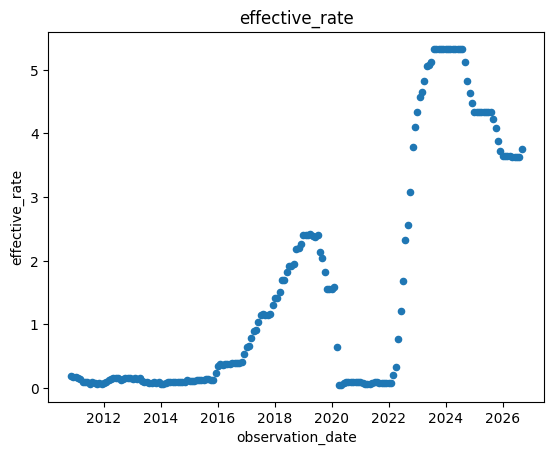

From 2010-11-01 00:00:00 to 2026-09-01 00:00:00


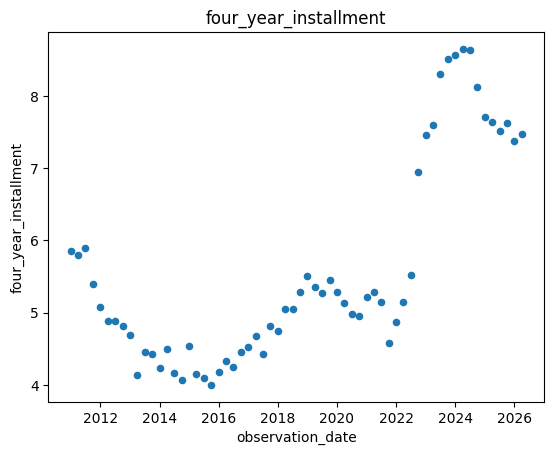

In [227]:
for column in imported_features.columns:
    if column != 'observation_date':
        kind = 'scatter'
        print(f"From {obmin} to {obmax}")
        imported_features.plot(x='observation_date', y= column,title=column, kind=kind)
        plt.show()




interpolate with forward fill so that future data doesn't leak into predictions

In [228]:
df = imported_features.copy().sort_values(by='observation_date',ascending=True)


,observation_date,effective_rate,four_year_installment
0,2010-11-01,0.19,NaN
1,2010-12-01,0.18,NaN


,observation_date,effective_rate,four_year_installment
189,2026-08-01,3.63,7.47
190,2026-09-01,3.75,7.47


From 2010-11-01 00:00:00 to 2026-09-01 00:00:00


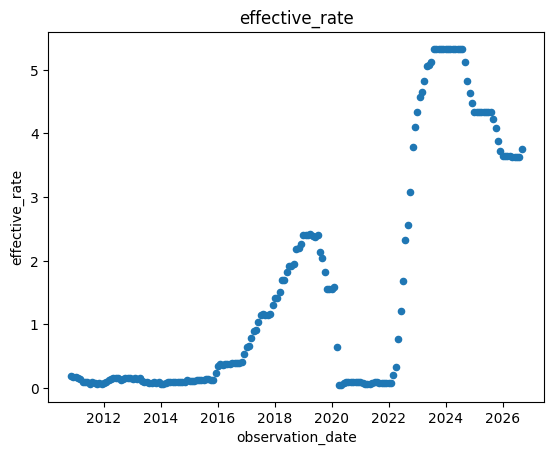

From 2010-11-01 00:00:00 to 2026-09-01 00:00:00


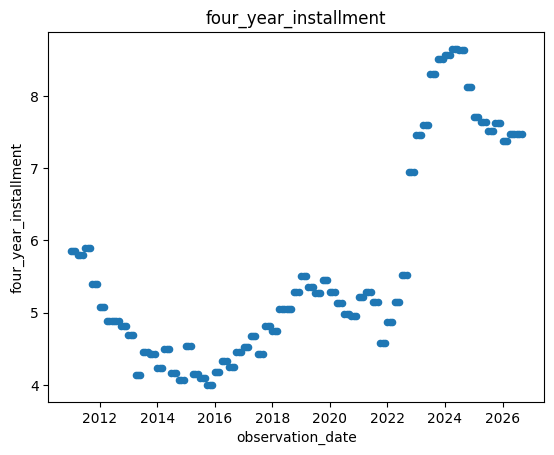

In [229]:
for column in df.columns:
    if column != 'observation_date':
        df[column] = df[column].ffill()
display(df.head(2))
display(df.tail(2))
for column in df.columns:
    if column!='observation_date':
        kind = 'scatter'
        print(f"From {obmin} to {obmax}")
        df.plot(x='observation_date', y= column,title=column, kind=kind)
        plt.show()




In [230]:

print('INCLUDING NAN')
print(df.shape)
print(df.isna().sum())
display(df.head(5))
display(df.tail(5))

df = df.dropna(axis=0)

print('EXCLUDING NAN')
print(df.shape)
print(df.isna().sum())
display(df.head(5))
display(df.tail(5))

INCLUDING NAN
(191, 3)
observation_date         0
effective_rate           0
four_year_installment    2
dtype: int64


,observation_date,effective_rate,four_year_installment
0,2010-11-01,0.19,NaN
1,2010-12-01,0.18,NaN
2,2011-01-01,0.17,5.85
3,2011-02-01,0.16,5.85
4,2011-03-01,0.14,5.85


,observation_date,effective_rate,four_year_installment
186,2026-05-01,3.63,7.47
187,2026-06-01,3.63,7.47
188,2026-07-01,3.63,7.47
189,2026-08-01,3.63,7.47
190,2026-09-01,3.75,7.47


EXCLUDING NAN
(189, 3)
observation_date         0
effective_rate           0
four_year_installment    0
dtype: int64


,observation_date,effective_rate,four_year_installment
2,2011-01-01,0.17,5.85
3,2011-02-01,0.16,5.85
4,2011-03-01,0.14,5.85
5,2011-04-01,0.10,5.79
6,2011-05-01,0.09,5.79


,observation_date,effective_rate,four_year_installment
186,2026-05-01,3.63,7.47
187,2026-06-01,3.63,7.47
188,2026-07-01,3.63,7.47
189,2026-08-01,3.63,7.47
190,2026-09-01,3.75,7.47


# build features  

In [231]:


def get_lag_chng_pctchng(data:pd.DataFrame=None,
                         colname:str=None,
                         i:int=None):
    data[f"lag_{i}_{colname}"] = data[colname].shift(periods=i)
    data[f"chng_lag_{i}_{colname}"] = data[colname]-data[f"lag_{i}_{colname}"]
    data[f"pct_chng_lag_{i}_{colname}"] = data[f"chng_lag_{i}_{colname}"]/data[colname]
    return data



In [232]:
# feature_engineered_rate_metrics (ferm)
ferm = df.copy() 
ferm.index = ferm['observation_date']
ferm = ferm.drop(columns='observation_date')  

for colname in ['four_year_installment','effective_rate']:
    for i in [1,2,3,4,5,6,7,8,9,10,11,12]:
        if ferm.isna().sum().sum()>0:
            raise ValueError('There are NaN in the Data. Cannot proceed.')
        ferm = get_lag_chng_pctchng(ferm,
                         colname=colname,
                         i=i)
        ferm = ferm.fillna(0)


features = ferm.copy()




In [233]:

# cyclical encoding of month, so December (12) sits next to January (1)
month = features.index.month
features['month_sin'] = np.sin(2 * np.pi * month / 12)
features['month_cos'] = np.cos(2 * np.pi * month / 12)
day = features.index.dayofyear
features['day_sin']   = np.sin(2 * np.pi * day / 365.25)
for col in features.columns:
    for pow in [2,3,4]:
        features[f"power{pow}_{col}"] = features[col]**pow

In [234]:
# add epsilon
features += 0.0000000001


In [235]:
pd.set_option("display.max_columns", None)
features.sample(15)

,effective_rate,four_year_installment,lag_1_four_year_installment,chng_lag_1_four_year_installment,pct_chng_lag_1_four_year_installment,lag_2_four_year_installment,chng_lag_2_four_year_installment,pct_chng_lag_2_four_year_installment,lag_3_four_year_installment,chng_lag_3_four_year_installment,pct_chng_lag_3_four_year_installment,lag_4_four_year_installment,chng_lag_4_four_year_installment,pct_chng_lag_4_four_year_installment,lag_5_four_year_installment,chng_lag_5_four_year_installment,pct_chng_lag_5_four_year_installment,lag_6_four_year_installment,chng_lag_6_four_year_installment,pct_chng_lag_6_four_year_installment,lag_7_four_year_installment,chng_lag_7_four_year_installment,pct_chng_lag_7_four_year_installment,lag_8_four_year_installment,chng_lag_8_four_year_installment,pct_chng_lag_8_four_year_installment,lag_9_four_year_installment,chng_lag_9_four_year_installment,pct_chng_lag_9_four_year_installment,lag_10_four_year_installment,chng_lag_10_four_year_installment,pct_chng_lag_10_four_year_installment,lag_11_four_year_installment,chng_lag_11_four_year_installment,pct_chng_lag_11_four_year_installment,lag_12_four_year_installment,chng_lag_12_four_year_installment,pct_chng_lag_12_four_year_installment,lag_1_effective_rate,chng_lag_1_effective_rate,pct_chng_lag_1_effective_rate,lag_2_effective_rate,chng_lag_2_effective_rate,pct_chng_lag_2_effective_rate,lag_3_effective_rate,chng_lag_3_effective_rate,pct_chng_lag_3_effective_rate,lag_4_effective_rate,chng_lag_4_effective_rate,pct_chng_lag_4_effective_rate,lag_5_effective_rate,chng_lag_5_effective_rate,pct_chng_lag_5_effective_rate,lag_6_effective_rate,chng_lag_6_effective_rate,pct_chng_lag_6_effective_rate,lag_7_effective_rate,chng_lag_7_effective_rate,pct_chng_lag_7_effective_rate,lag_8_effective_rate,chng_lag_8_effective_rate,pct_chng_lag_8_effective_rate,lag_9_effective_rate,chng_lag_9_effective_rate,pct_chng_lag_9_effective_rate,lag_10_effective_rate,chng_lag_10_effective_rate,pct_chng_lag_10_effective_rate,lag_11_effective_rate,chng_lag_11_effective_rate,pct_chng_lag_11_effective_rate,lag_12_effective_rate,chng_lag_12_effective_rate,pct_chng_lag_12_effective_rate,month_sin,month_cos,day_sin,power2_effective_rate,power3_effective_rate,power4_effective_rate,power2_four_year_installment,power3_four_year_installment,power4_four_year_installment,power2_lag_1_four_year_installment,power3_lag_1_four_year_installment,power4_lag_1_four_year_installment,power2_chng_lag_1_four_year_installment,power3_chng_lag_1_four_year_installment,power4_chng_lag_1_four_year_installment,power2_pct_chng_lag_1_four_year_installment,power3_pct_chng_lag_1_four_year_installment,power4_pct_chng_lag_1_four_year_installment,power2_lag_2_four_year_installment,power3_lag_2_four_year_installment,power4_lag_2_four_year_installment,power2_chng_lag_2_four_year_installment,power3_chng_lag_2_four_year_installment,power4_chng_lag_2_four_year_installment,power2_pct_chng_lag_2_four_year_installment,power3_pct_chng_lag_2_four_year_installment,power4_pct_chng_lag_2_four_year_installment,power2_lag_3_four_year_installment,power3_lag_3_four_year_installment,power4_lag_3_four_year_installment,power2_chng_lag_3_four_year_installment,power3_chng_lag_3_four_year_installment,power4_chng_lag_3_four_year_installment,power2_pct_chng_lag_3_four_year_installment,power3_pct_chng_lag_3_four_year_installment,power4_pct_chng_lag_3_four_year_installment,power2_lag_4_four_year_installment,power3_lag_4_four_year_installment,power4_lag_4_four_year_installment,power2_chng_lag_4_four_year_installment,power3_chng_lag_4_four_year_installment,power4_chng_lag_4_four_year_installment,power2_pct_chng_lag_4_four_year_installment,power3_pct_chng_lag_4_four_year_installment,power4_pct_chng_lag_4_four_year_installment,power2_lag_5_four_year_installment,power3_lag_5_four_year_installment,power4_lag_5_four_year_installment,power2_chng_lag_5_four_year_installment,power3_chng_lag_5_four_year_installment,power4_chng_lag_5_four_year_installment,power2_pct

# Targets  
there will be a production workflow that agents verify data format. possibly format it. likely map models to categories. there may also be a cut and paste prompt for consumers to aid in data prep.   

input data would then follow a concatination workflow sililar to below

In [236]:
cars = pd.read_csv('archive_data/sufficient_data/base_montly_carsales_for_2014_to_2026_for_ML_targets.csv')
cars.head()

,date,year,month,model_name,sales_units,source_value,value_status,reporting_basis,country,source_url
0,2014-01-01,2014,1,Acura ILX,1157.0,1157.0,numeric,not_verified,USA,https://www.goodcarbadcar.net/acura-ilx-sales-...
1,2014-02-01,2014,2,Acura ILX,1301.0,1301.0,numeric,not_verified,USA,https://www.goodcarbadcar.net/acura-ilx-sales-...
2,2014-03-01,2014,3,Acura ILX,1683.0,1683.0,numeric,not_verified,USA,https://www.goodcarbadcar.net/acura-ilx-sales-...
3,2014-04-01,2014,4,Acura ILX,1659.0,1659.0,numeric,not_verified,USA,https://www.goodcarbadcar.net/acura-ilx-sales-...
4,2014-05-01,2014,5,Acura ILX,1629.0,1629.0,numeric,not_verified,USA,https://www.goodcarbadcar.net/acura-ilx-sales-...


In [237]:
cars.dtypes

date                object
year                 int64
month                int64
model_name          object
sales_units        float64
source_value       float64
value_status        object
reporting_basis     object
country             object
source_url          object
dtype: object

In [238]:
cars['date'] = pd.to_datetime(cars['date'],yearfirst=True, errors='raise')

In [239]:
cars.dtypes

date               datetime64[ns]
year                        int64
month                       int64
model_name                 object
sales_units               float64
source_value              float64
value_status               object
reporting_basis            object
country                    object
source_url                 object
dtype: object

In [240]:
unq = cars['model_name'].str.strip().str.lower().dropna().unique()
models = pd.DataFrame(unq,columns=['unique_models'])


In [241]:
import json
with open('archive_data/sufficient_data/car_model_styles_updated_2014_to_2026.json', 'r') as f:
    my_maps = json.load(f)
print(f"Style Definitions: \n",my_maps['style_definitions'])
types = my_maps['model_to_style']
types = dict(types)
types

Style Definitions: 
 {'sedan': 'Passenger car with a conventional separate trunk. Performance and luxury sedans remain sedans.', 'hatchback_liftback': 'Passenger car with a rear hatch or liftgate, including fastback liftbacks and tall hatchbacks.', 'wagon': 'Passenger wagon or estate with an extended roof and rear cargo area.', 'sports_car': 'Dedicated sports cars, roadsters and pony/muscle cars. Includes coupe and convertible variants. Performance trims of sedans, SUVs and pickups stay in their underlying class.', 'coupe_convertible': 'Other two-door coupes, grand tourers and convertibles, grouped together to keep category count compact.', 'suv_crossover': 'SUVs and crossovers, including coupe-roof SUVs, all sizes, luxury and performance variants.', 'pickup_truck': 'Open-bed pickup nameplates, including compact, midsize, full-size and combined light/heavy-duty families.', 'minivan': 'Primarily passenger-oriented minivans/MPVs, including Volkswagen ID. Buzz.', 'commercial_van': 'Cargo,

{'acura adx': 'suv_crossover',
 'acura ilx': 'sedan',
 'acura integra': 'hatchback_liftback',
 'acura mdx': 'suv_crossover',
 'acura nsx': 'sports_car',
 'acura rdx': 'suv_crossover',
 'acura tlx': 'sedan',
 'acura zdx': 'suv_crossover',
 'alfa romeo 4c': 'sports_car',
 'alfa romeo giulia': 'sedan',
 'alfa romeo spider': 'sports_car',
 'alfa romeo stelvio': 'suv_crossover',
 'alfa romeo tonale': 'suv_crossover',
 'aston martin dbx': 'suv_crossover',
 'audi a3': 'mixed_body_style',
 'audi a4': 'mixed_body_style',
 'audi a5': 'mixed_body_style',
 'audi a6': 'mixed_body_style',
 'audi a6 sportback e-tron': 'hatchback_liftback',
 'audi a7': 'hatchback_liftback',
 'audi a8': 'sedan',
 'audi e-tron gt': 'sedan',
 'audi etron': 'suv_crossover',
 'audi q3': 'suv_crossover',
 'audi q4 e-tron': 'suv_crossover',
 'audi q4 e-tron sportback': 'suv_crossover',
 'audi q5': 'suv_crossover',
 'audi q6 e-tron': 'suv_crossover',
 'audi q6 sportback e-tron': 'suv_crossover',
 'audi q7': 'suv_crossover',
 

In [242]:
cars['model_type'] = cars['model_name'].str.strip().str.lower().map(types)
pipe_cars = cars[['date','year','month','model_name','model_type','source_value']]
pipe_cars.head()

,date,year,month,model_name,model_type,source_value
0,2014-01-01,2014,1,Acura ILX,sedan,1157.0
1,2014-02-01,2014,2,Acura ILX,sedan,1301.0
2,2014-03-01,2014,3,Acura ILX,sedan,1683.0
3,2014-04-01,2014,4,Acura ILX,sedan,1659.0
4,2014-05-01,2014,5,Acura ILX,sedan,1629.0


In [243]:
def str_to_int(x):
    res = ''
    if x:
        for i in x:
            strnum = str(i)
            if strnum in '1234567890':
                res += strnum
    if res:
        return int(res)
    else:
        return 0

pipe_cars['source_value'] = pipe_cars['source_value'].astype(str).map(str_to_int)
type_sums_df = pipe_cars.groupby(['date',
                                  'year',
                                  'month',
                                  'model_type'],as_index=False)['source_value'].sum()
type_sums_df = type_sums_df.sort_values(by=['year','month','source_value','model_type'],ascending=[True,True,False,False]).reset_index(drop=True)
display(type_sums_df.head(3))
display(type_sums_df.tail(3))

,date,year,month,model_type,source_value
0,2014-01-01,2014,1,suv_crossover,3296890
1,2014-01-01,2014,1,sedan,1935920
2,2014-01-01,2014,1,mixed_body_style,1527050


,date,year,month,model_type,source_value
1197,2024-12-01,2024,12,sports_car,100270
1198,2024-12-01,2024,12,coupe_convertible,46910
1199,2024-12-01,2024,12,wagon,27940


In [244]:
r = type_sums_df.copy().groupby(['year','month'],as_index=False)['source_value'].max()
new = pd.merge(type_sums_df,r,
                           on=['year','month','source_value'],
                           how='inner')
new.sample(31)

                                                                              

,date,year,month,model_type,source_value
108,2023-01-01,2023,1,suv_crossover,6188880
107,2022-12-01,2022,12,suv_crossover,6783090
82,2020-11-01,2020,11,suv_crossover,6250220
3,2014-04-01,2014,4,suv_crossover,4415270
89,2021-06-01,2021,6,suv_crossover,7333530
25,2016-02-01,2016,2,suv_crossover,4975640
87,2021-04-01,2021,4,suv_crossover,8228560
124,2024-05-01,2024,5,suv_crossover,7904980
72,2020-01-01,2020,1,suv_crossover,5718010
16,2015-05-01,2015,5,suv_crossover,5784760


In [245]:


x, group, y = 'date', 'model_type', 'source_value'  

wide = type_sums_df.pivot_table(index=x, columns=group, values=y, aggfunc='sum').sort_index()
# order legend by most recent value so it matches the line order
wide = wide[wide.iloc[-1].sort_values(ascending=False).index]
display(wide.sample(5))


model_type,suv_crossover,pickup_truck,sedan,mixed_body_style,commercial_van,minivan,hatchback_liftback,sports_car,coupe_convertible,wagon
date,,,,,,,,,,
2020-05-01,5976170.0,2576400.0,1225850.0,968330.0,244680.0,163250.0,141680.0,176020.0,3820.0,NaN
2019-09-01,6162510.0,2405620.0,1649440.0,1169900.0,369380.0,267700.0,191140.0,188080.0,4140.0,NaN
2024-03-01,8284050.0,2173040.0,1326930.0,1097150.0,285680.0,237800.0,137210.0,170910.0,26260.0,0.0
2022-02-01,5906740.0,2048560.0,1071830.0,745290.0,208540.0,188420.0,127120.0,156780.0,2800.0,NaN
2020-01-01,5718010.0,2185580.0,1495100.0,963390.0,289370.0,256200.0,167210.0,158380.0,3870.0,NaN


model_type,suv_crossover,pickup_truck,sedan,mixed_body_style,commercial_van,minivan,hatchback_liftback,sports_car,coupe_convertible,wagon
date,,,,,,,,,,
2014-01-01,3296890.0,1364100.0,1935920.0,1527050.0,161430.0,228650.0,227190.0,158840.0,11070.0,NaN
2014-02-01,3889590.0,1629440.0,2361440.0,1705340.0,183630.0,268790.0,238930.0,215390.0,13630.0,NaN
2014-03-01,4879880.0,2086220.0,3083790.0,2266430.0,232110.0,362000.0,335080.0,304630.0,18600.0,NaN
2014-04-01,4415270.0,1921390.0,2680490.0,2052520.0,269100.0,361250.0,320070.0,283470.0,16030.0,NaN
2014-05-01,5146910.0,2051460.0,3107040.0,2399190.0,319620.0,404770.0,416160.0,327550.0,19210.0,NaN
...,...,...,...,...,...,...,...,...,...,...
2024-08-01,8415080.0,2722190.0,1252620.0,1092510.0,366520.0,219120.0,165410.0,116170.0,50720.0,5700.0
2024-09-01,6710320.0,2248440.0,1053820.0,846190.0,303410.0,190780.0,131450.0,94690.0,41380.0,17110.0
2024-10-01,7450350.0,2475150.0,1105340.0,954580.0,323700.0,222640.0,109280.0,97010.0,38760.0,24210.0


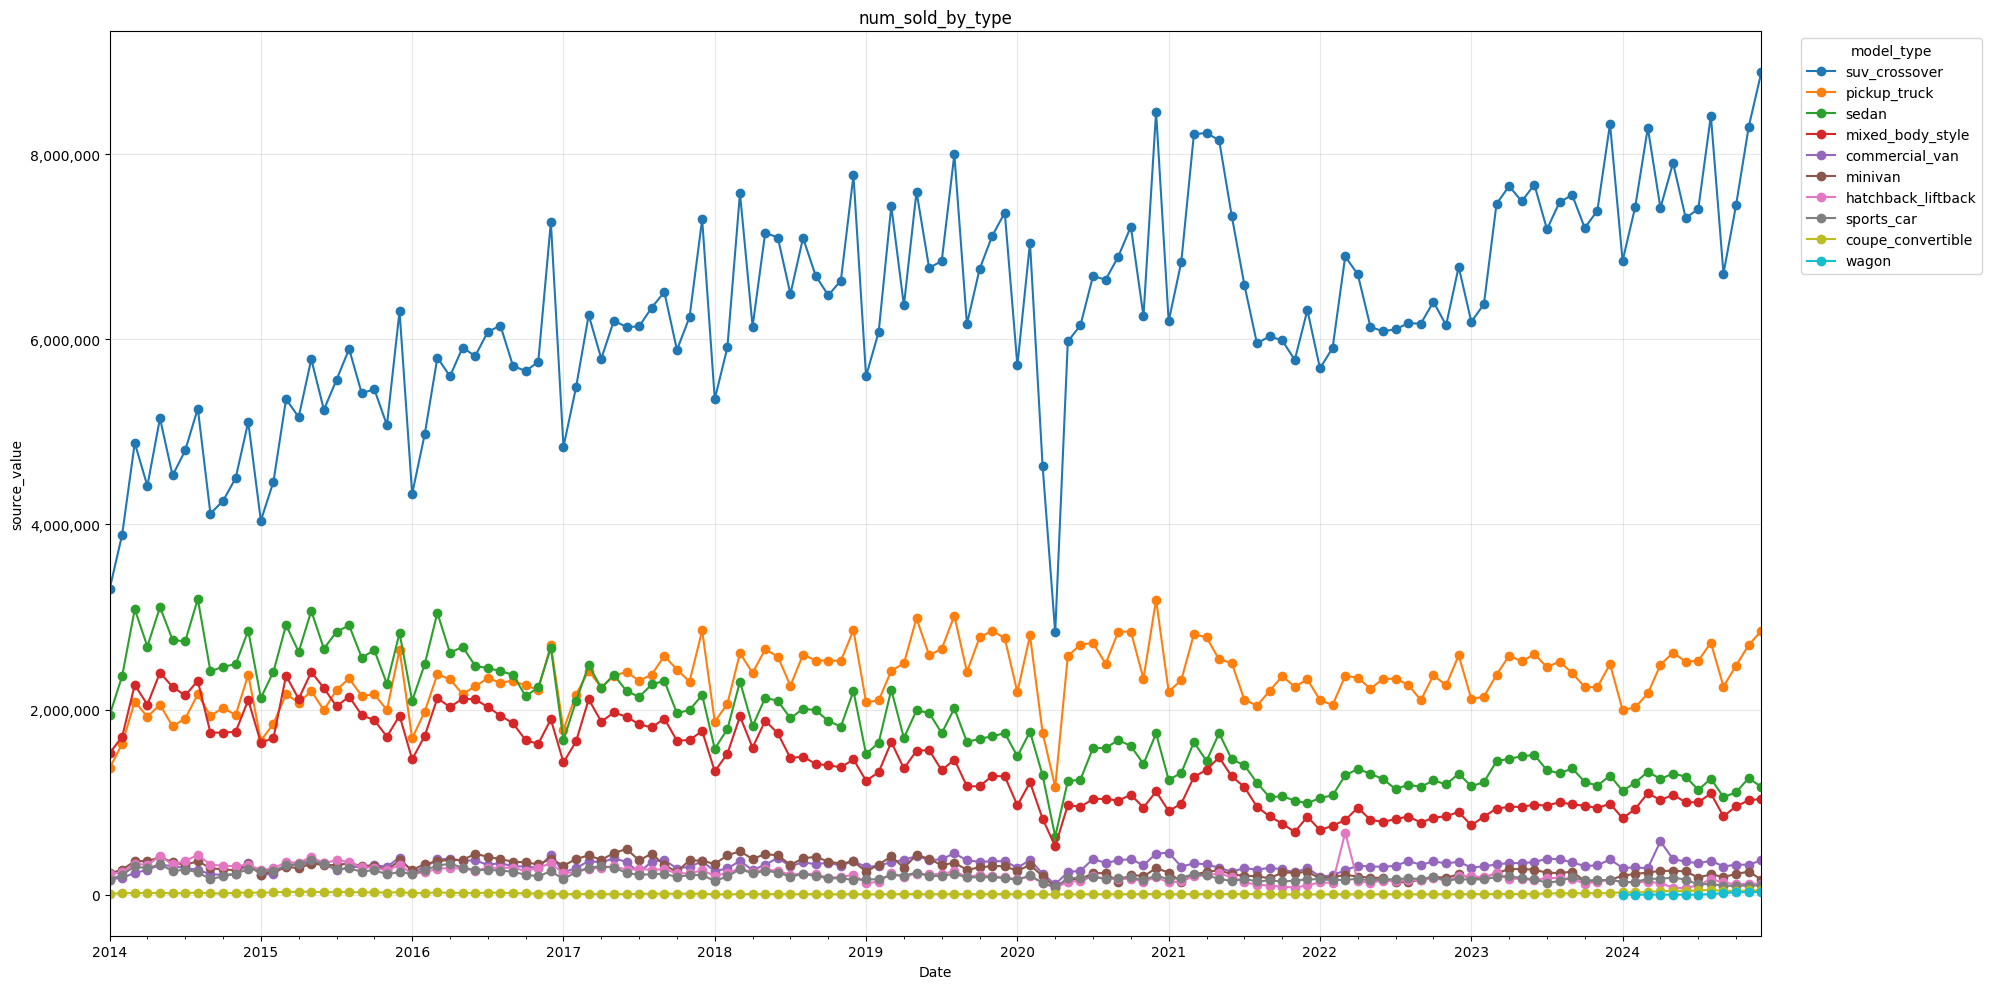

In [246]:



def plot_wide(data:pd.DataFrame,
              title:str): 
                
    figsize=(20,10)
    ax = data.plot(figsize=figsize, marker='o', colormap='tab10')
    ax.set_title(title)
    ax.set_xlabel('Date')
    ax.set_ylabel(y)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.legend(title='model_type', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

display(wide)
plot_wide(wide,'num_sold_by_type')


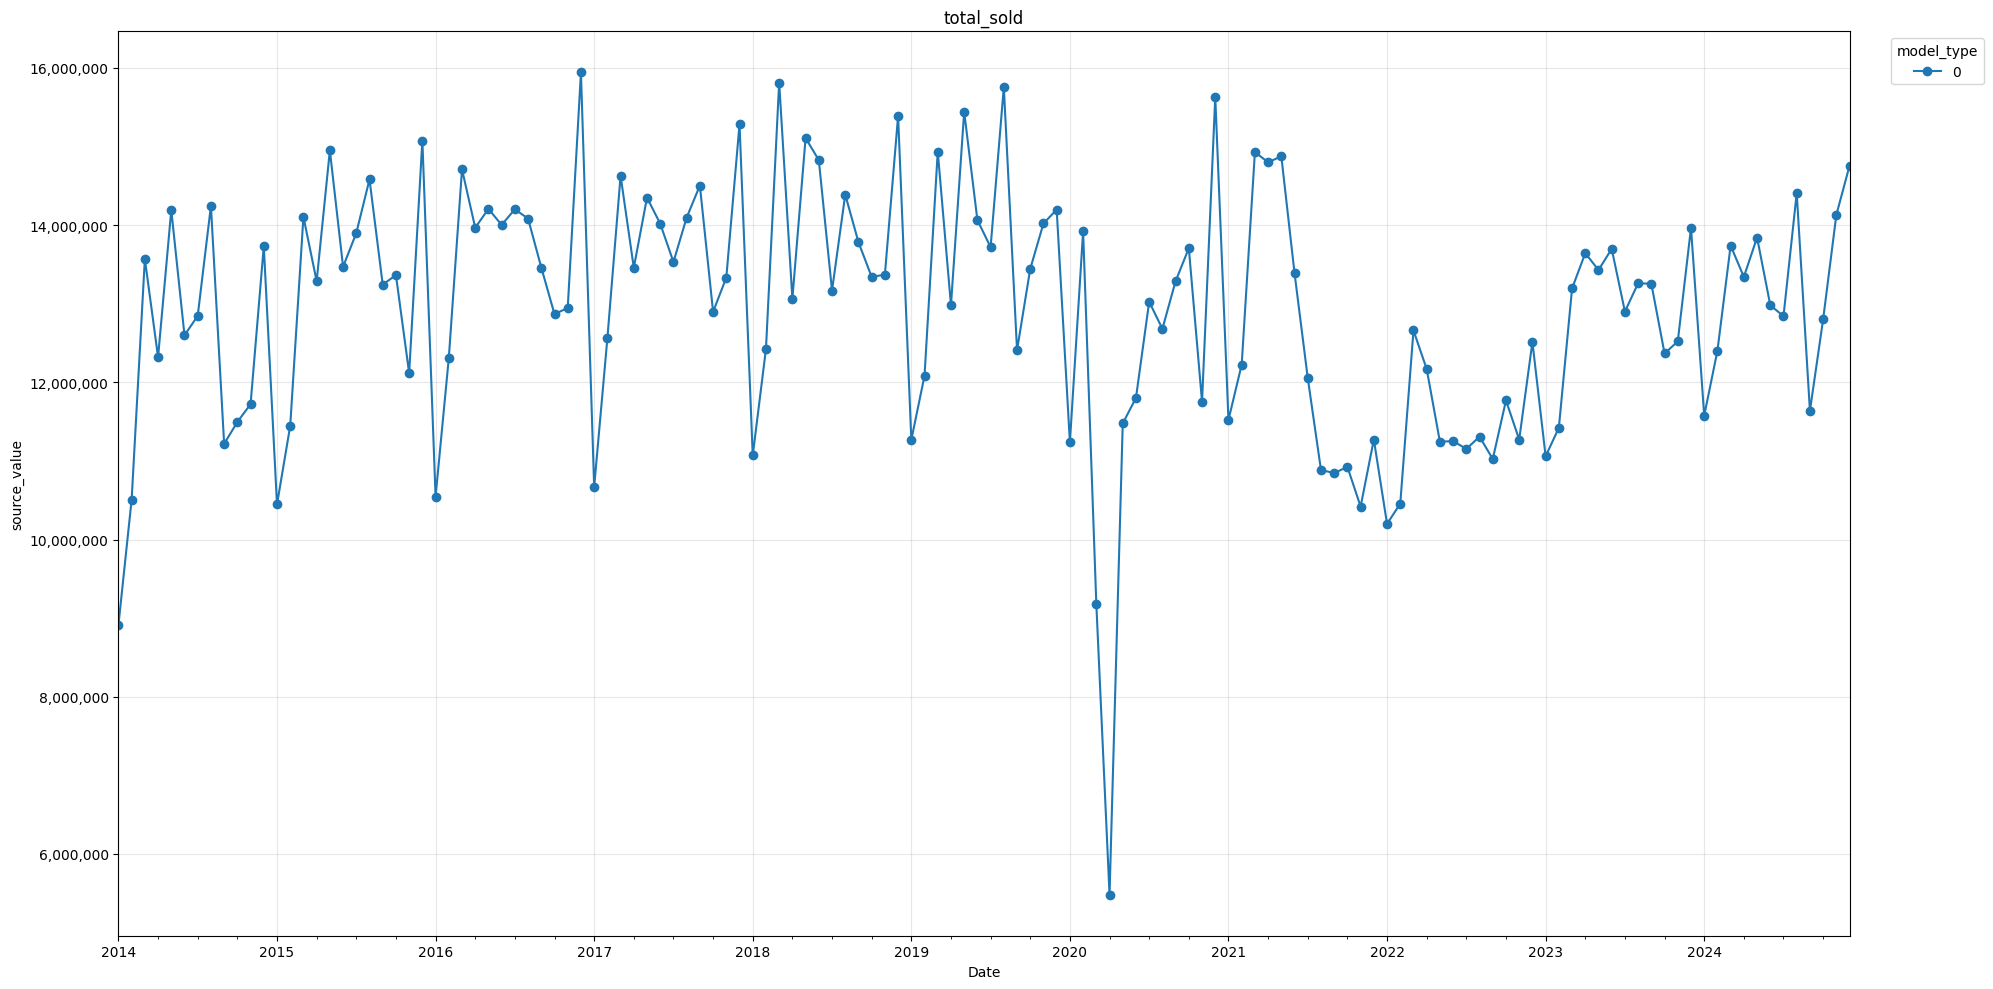

In [247]:
totals = pd.DataFrame(wide.sum(axis=1),index=wide.index)
plot_wide(totals,'total_sold')

In [248]:
plot_pct_data = pd.DataFrame(index=wide.index)
plot_pct_data['totals'] = wide.sum(axis=1)
for col in wide.columns:
    plot_pct_data[f"{col}_pct"] = wide[col]/plot_pct_data['totals']
plot_pct_data = plot_pct_data.drop(columns='totals')

,suv_crossover_pct,pickup_truck_pct,sedan_pct,mixed_body_style_pct,commercial_van_pct,minivan_pct,hatchback_liftback_pct,sports_car_pct,coupe_convertible_pct,wagon_pct
date,,,,,,,,,,
2014-01-01,0.369974,0.153078,0.217247,0.171364,0.018116,0.025659,0.025495,0.017825,0.001242,NaN
2014-02-01,0.370219,0.155093,0.224767,0.162318,0.017478,0.025584,0.022742,0.020501,0.001297,NaN
2014-03-01,0.359641,0.153752,0.227272,0.167033,0.017106,0.026679,0.024695,0.022451,0.001371,NaN
2014-04-01,0.358394,0.155962,0.217579,0.166606,0.021843,0.029323,0.025981,0.023010,0.001301,NaN
2014-05-01,0.362665,0.144551,0.218930,0.169053,0.022521,0.028521,0.029324,0.023080,0.001354,NaN
...,...,...,...,...,...,...,...,...,...,...
2024-08-01,0.584136,0.188962,0.086951,0.075837,0.025442,0.015210,0.011482,0.008064,0.003521,0.000396
2024-09-01,0.576607,0.193205,0.090553,0.072712,0.026072,0.016393,0.011295,0.008137,0.003556,0.001470
2024-10-01,0.582012,0.193356,0.086348,0.074571,0.025287,0.017392,0.008537,0.007578,0.003028,0.001891


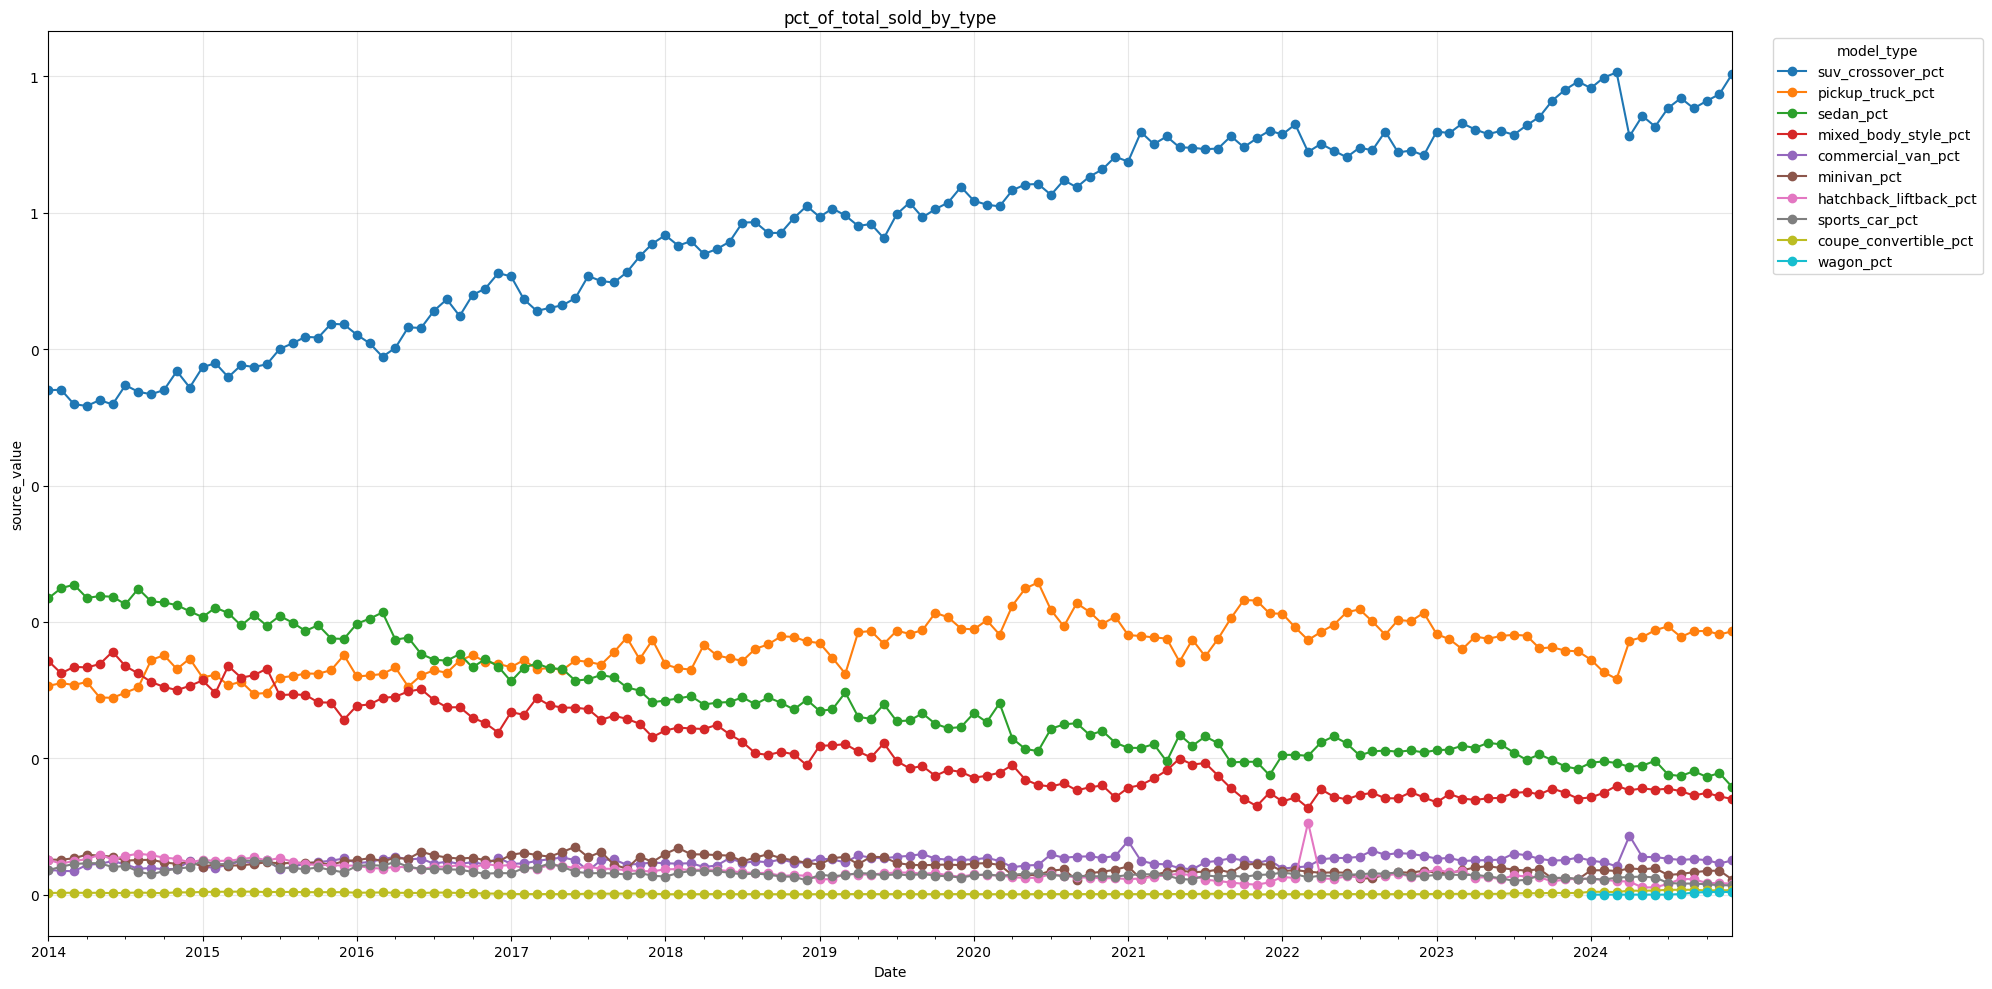

In [249]:
display(plot_pct_data)
plot_wide(plot_pct_data,'pct_of_total_sold_by_type')

In [250]:
plot_pct_data.index = plot_pct_data.index.astype('datetime64[ns]')

                       

In [251]:
print(wide.shape)
wide.isna().sum()

(132, 10)


model_type
suv_crossover           0
pickup_truck            0
sedan                   0
mixed_body_style        0
commercial_van          0
minivan                 0
hatchback_liftback      0
sports_car              0
coupe_convertible       0
wagon                 120
dtype: int64

In [252]:
wide = wide.fillna(1)

# target

In [253]:
wide['total_sold'] = wide.sum(axis=1)
for col in wide.columns:
    if col != 'total_sold':
        wide[f"{col}_pct_of_total"] = round(wide[col] / wide['total_sold'],3)
wide.sample(31)

model_type,suv_crossover,pickup_truck,sedan,mixed_body_style,commercial_van,minivan,hatchback_liftback,sports_car,coupe_convertible,wagon,total_sold,suv_crossover_pct_of_total,pickup_truck_pct_of_total,sedan_pct_of_total,mixed_body_style_pct_of_total,commercial_van_pct_of_total,minivan_pct_of_total,hatchback_liftback_pct_of_total,sports_car_pct_of_total,coupe_convertible_pct_of_total,wagon_pct_of_total
date,,,,,,,,,,,,,,,,,,,,,
2016-03-01,5802480.0,2380180.0,3044120.0,2122430.0,382390.0,361450.0,280740.0,312480.0,23230.0,1.0,14709501.0,0.394,0.162,0.207,0.144,0.026,0.025,0.019,0.021,0.002,0.0
2024-05-01,7904980.0,2613800.0,1308400.0,1078600.0,381950.0,257610.0,73030.0,183360.0,39800.0,0.0,13841530.0,0.571,0.189,0.095,0.078,0.028,0.019,0.005,0.013,0.003,0.0
2017-05-01,6201690.0,2364290.0,2375010.0,1967600.0,390660.0,449390.0,304960.0,290830.0,5170.0,1.0,14349601.0,0.432,0.165,0.166,0.137,0.027,0.031,0.021,0.020,0.000,0.0
2024-07-01,7406490.0,2526000.0,1130850.0,997960.0,337930.0,184270.0,101490.0,110000.0,45210.0,0.0,12840200.0,0.577,0.197,0.088,0.078,0.026,0.014,0.008,0.009,0.004,0.0
2022-01-01,5685580.0,2101240.0,1045010.0,696530.0,195100.0,175020.0,132340.0,165120.0,3050.0,1.0,10198991.0,0.557,0.206,0.102,0.068,0.019,0.017,0.013,0.016,0.000,0.0
2016-10-01,5657470.0,2259380.0,2143810.0,1669620.0,305020.0,348020.0,254540.0,214060.0,14560.0,1.0,12866481.0,0.440,0.176,0.167,0.130,0.024,0.027,0.020,0.017,0.001,0.0
2018-02-01,5911680.0,2061110.0,1787350.0,1521920.0,282230.0,424710.0,232430.0,196790.0,3140.0,1.0,12421361.0,0.476,0.166,0.144,0.123,0.023,0.034,0.019,0.016,0.000,0.0
2020-02-01,7042880.0,2800720.0,1760440.0,1213120.0,374640.0,320680.0,196060.0,206980.0,3850.0,1.0,13919371.0,0.506,0.201,0.126,0.087,0.027,0.023,0.014,0.015,0.000,0.0
2019-11-01,7115620.0,2851550.0,1710610.0,1282200.0,359190.0,309330.0,197940.0,188600.0,5360.0,1.0,14020401.0,0.508,0.203,0.122,0.091,0.026,0.022,0.014,0.013,0.000,0.0


# concatenate the data we already have on file. in this case 2025 and 2026.  
for production there would be a date continuety step  

In [254]:
wide.index.max()
display(wide.head(2))
display(wide.tail(2))
recent_years = pd.read_csv("archive_data/exploratory_data/car_sales_prediciton_targetsOctober2026.csv")
recent_years = recent_years.set_index('date')
display(recent_years.head(2))
display(recent_years.tail(2))
wide.columns == recent_years.columns

model_type,suv_crossover,pickup_truck,sedan,mixed_body_style,commercial_van,minivan,hatchback_liftback,sports_car,coupe_convertible,wagon,total_sold,suv_crossover_pct_of_total,pickup_truck_pct_of_total,sedan_pct_of_total,mixed_body_style_pct_of_total,commercial_van_pct_of_total,minivan_pct_of_total,hatchback_liftback_pct_of_total,sports_car_pct_of_total,coupe_convertible_pct_of_total,wagon_pct_of_total
date,,,,,,,,,,,,,,,,,,,,,
2014-01-01,3296890.0,1364100.0,1935920.0,1527050.0,161430.0,228650.0,227190.0,158840.0,11070.0,1.0,8911141.0,0.37,0.153,0.217,0.171,0.018,0.026,0.025,0.018,0.001,0.0
2014-02-01,3889590.0,1629440.0,2361440.0,1705340.0,183630.0,268790.0,238930.0,215390.0,13630.0,1.0,10506181.0,0.37,0.155,0.225,0.162,0.017,0.026,0.023,0.021,0.001,0.0


model_type,suv_crossover,pickup_truck,sedan,mixed_body_style,commercial_van,minivan,hatchback_liftback,sports_car,coupe_convertible,wagon,total_sold,suv_crossover_pct_of_total,pickup_truck_pct_of_total,sedan_pct_of_total,mixed_body_style_pct_of_total,commercial_van_pct_of_total,minivan_pct_of_total,hatchback_liftback_pct_of_total,sports_car_pct_of_total,coupe_convertible_pct_of_total,wagon_pct_of_total
date,,,,,,,,,,,,,,,,,,,,,
2024-11-01,8294550.0,2696540.0,1259810.0,1017850.0,323450.0,248800.0,118300.0,98010.0,44670.0,27670.0,14129650.0,0.587,0.191,0.089,0.072,0.023,0.018,0.008,0.007,0.003,0.002
2024-12-01,8882930.0,2848940.0,1162720.0,1034870.0,369360.0,162630.0,119610.0,100270.0,46910.0,27940.0,14756180.0,0.602,0.193,0.079,0.070,0.025,0.011,0.008,0.007,0.003,0.002


,suv_crossover,pickup_truck,sedan,mixed_body_style,minivan,commercial_van,sports_car,hatchback_liftback,wagon,coupe_convertible,total_sold,suv_crossover_pct_of_total,pickup_truck_pct_of_total,sedan_pct_of_total,mixed_body_style_pct_of_total,minivan_pct_of_total,commercial_van_pct_of_total,sports_car_pct_of_total,hatchback_liftback_pct_of_total,wagon_pct_of_total,coupe_convertible_pct_of_total
date,,,,,,,,,,,,,,,,,,,,,
2025-01-01,702361,224908,104806,90815,27369,23967,8732,9441,2565,1443,1196407,0.587,0.188,0.088,0.076,0.023,0.020,0.007,0.008,0.002,0.001
2025-02-01,726678,221597,105730,92405,31015,30124,8352,8945,2537,1510,1228893,0.591,0.180,0.086,0.075,0.025,0.025,0.007,0.007,0.002,0.001


,suv_crossover,pickup_truck,sedan,mixed_body_style,minivan,commercial_van,sports_car,hatchback_liftback,wagon,coupe_convertible,total_sold,suv_crossover_pct_of_total,pickup_truck_pct_of_total,sedan_pct_of_total,mixed_body_style_pct_of_total,minivan_pct_of_total,commercial_van_pct_of_total,sports_car_pct_of_total,hatchback_liftback_pct_of_total,wagon_pct_of_total,coupe_convertible_pct_of_total
date,,,,,,,,,,,,,,,,,,,,,
2026-08-01,713017,271969,89087,92725,35613,28721,8500,6983,2493,156,1249264,0.571,0.218,0.071,0.074,0.029,0.023,0.007,0.006,0.002,0.0
2026-09-01,673334,264423,82653,81039,37726,28582,7227,6300,2056,105,1183445,0.569,0.223,0.070,0.068,0.032,0.024,0.006,0.005,0.002,0.0


array([ True,  True,  True,  True, False, False, False, False, False,
       False,  True,  True,  True,  True,  True, False, False, False,
       False, False, False])

In [255]:
wide_columns = sorted(list(wide.columns))
recent_columns = sorted(list(recent_years.columns))
wide_columns == recent_columns

True

In [256]:
wide = wide[wide_columns]
recent_years = recent_years[recent_columns]
wide.columns == recent_years.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True])

In [257]:
print(wide.shape)
wide = pd.concat([wide, recent_years])
print(wide.shape)
display(wide.head(2))
display(wide.tail(2))

(132, 21)
(153, 21)


,commercial_van,commercial_van_pct_of_total,coupe_convertible,coupe_convertible_pct_of_total,hatchback_liftback,hatchback_liftback_pct_of_total,minivan,minivan_pct_of_total,mixed_body_style,mixed_body_style_pct_of_total,pickup_truck,pickup_truck_pct_of_total,sedan,sedan_pct_of_total,sports_car,sports_car_pct_of_total,suv_crossover,suv_crossover_pct_of_total,total_sold,wagon,wagon_pct_of_total
date,,,,,,,,,,,,,,,,,,,,,
2014-01-01 00:00:00,161430.0,0.018,11070.0,0.001,227190.0,0.025,228650.0,0.026,1527050.0,0.171,1364100.0,0.153,1935920.0,0.217,158840.0,0.018,3296890.0,0.37,8911141.0,1.0,0.0
2014-02-01 00:00:00,183630.0,0.017,13630.0,0.001,238930.0,0.023,268790.0,0.026,1705340.0,0.162,1629440.0,0.155,2361440.0,0.225,215390.0,0.021,3889590.0,0.37,10506181.0,1.0,0.0


,commercial_van,commercial_van_pct_of_total,coupe_convertible,coupe_convertible_pct_of_total,hatchback_liftback,hatchback_liftback_pct_of_total,minivan,minivan_pct_of_total,mixed_body_style,mixed_body_style_pct_of_total,pickup_truck,pickup_truck_pct_of_total,sedan,sedan_pct_of_total,sports_car,sports_car_pct_of_total,suv_crossover,suv_crossover_pct_of_total,total_sold,wagon,wagon_pct_of_total
date,,,,,,,,,,,,,,,,,,,,,
2026-08-01,28721.0,0.023,156.0,0.0,6983.0,0.006,35613.0,0.029,92725.0,0.074,271969.0,0.218,89087.0,0.071,8500.0,0.007,713017.0,0.571,1249264.0,2493.0,0.002
2026-09-01,28582.0,0.024,105.0,0.0,6300.0,0.005,37726.0,0.032,81039.0,0.068,264423.0,0.223,82653.0,0.070,7227.0,0.006,673334.0,0.569,1183445.0,2056.0,0.002


In [258]:
wide.isna().sum()

commercial_van                     0
commercial_van_pct_of_total        0
coupe_convertible                  0
coupe_convertible_pct_of_total     0
hatchback_liftback                 0
hatchback_liftback_pct_of_total    0
minivan                            0
minivan_pct_of_total               0
mixed_body_style                   0
mixed_body_style_pct_of_total      0
pickup_truck                       0
pickup_truck_pct_of_total          0
sedan                              0
sedan_pct_of_total                 0
sports_car                         0
sports_car_pct_of_total            0
suv_crossover                      0
suv_crossover_pct_of_total         0
total_sold                         0
wagon                              0
wagon_pct_of_total                 0
dtype: int64

In [ ]:
stop cell to prevent overwriting

NameError: name 'hhh' is not defined

# save features and targets to csv

In [ ]:
print(features.isna().sum().sum())
print(wide.isna().sum().sum())

0
0


In [ ]:
wide.to_csv('car_sales_prediciton_targets.csv',index=True, encoding='utf-8')
features.to_csv('car_sales_prediction_features.csv',index=True, encoding='utf-8')

In [ ]:
print(f"HEADERS\n{'*'*50}\n")
print(wide.shape,wide.columns)
print('*'*50)
print(features.shape,features.columns)

(21, 21) Index(['suv_crossover', 'pickup_truck', 'sedan', 'mixed_body_style', 'minivan',
       'commercial_van', 'sports_car', 'hatchback_liftback', 'wagon',
       'coupe_convertible', 'total_sold', 'suv_crossover_pct_of_total',
       'pickup_truck_pct_of_total', 'sedan_pct_of_total',
       'mixed_body_style_pct_of_total', 'minivan_pct_of_total',
       'commercial_van_pct_of_total', 'sports_car_pct_of_total',
       'hatchback_liftback_pct_of_total', 'wagon_pct_of_total',
       'coupe_convertible_pct_of_total'],
      dtype='object', name='model_type')
v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^v^
(21, 308) Index(['fy_value', 'er_value', 'lag_1_fy_value', 'chng_lag_1_fy_value',
       'pct_chng_lag_1_fy_value', 'lag_2_fy_value', 'chng_lag_2_fy_value',
       'pct_chng_lag_2_fy_value', 'lag_3_fy_value', 'chng_lag_3_fy_value',
       ...
       'power4_pct_chng_lag_12_er_value', 'power2_month_sin',
       'power3_month_sin', 'p

In [ ]:
# date normalization
current = pd.read_csv('car_sales_prediciton_targets.csv')
current.head()
current = current.rename(columns = {'date':'observation_date'})
current['observation_date'] = pd.to_datetime(current['observation_date'].astype(str).str[:10],
                                             errors='raise')
current.head()
current.to_csv('car_sales_prediction_targets.csv',index=False,encoding='utf-8')